# Análisis exploratorio e indicadores oceanográficos

**Objetivos**.
Analizar la estructura vertical de temperatura, salinidad, oxígeno, nutrientes y clorofila. Calcular indicadores como profundidad de la capa de mezcla (MLD); inyección de nutrientes en capa de mezcla (RSI); profundidad y magnitud del máximo de clorofila (DCM y concentración máxima); e indicadores fenológicos: inicio, máximo, duración e intensidad de la temporada de crecimiento.

**Datasets utilizados** Por simplicidad, se utiliza el dataset simulado por GOTM-FABM en configuración vertical (1D) en la estación E2GI entre 20XX y 20XX. Contiene un perfil vertical con las medias diarias (de temperatura, nutrientes y clorofila, entre otras) en cada día de simulación. Este dataset, junto con los indicadres derivados, se usa  también en el **NB04** para la aplicación de ML. Al final de este notebook se formatea para que pueda ser leído como df pandas en el **NB04**.

## 1. Exploración de las variables originales

In [3]:
install.packages("RNetCDF")

Warning message:
"package 'RNetCDF' is in use and will not be installed"


In [5]:
if (require(plot3D)==FALSE) install.packages("plot3D")

Cargando paquete requerido: plot3D

Warning message in library(package, lib.loc = lib.loc, character.only = TRUE, logical.return = TRUE, :
"no hay paquete llamado 'plot3D'"
also installing the dependency 'misc3d'




package 'misc3d' successfully unpacked and MD5 sums checked
package 'plot3D' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\eva.alvarez\AppData\Local\Temp\RtmpaOaw8x\downloaded_packages


In [6]:
library(RNetCDF)
library(lubridate)
library(plot3D)
library(viridisLite)

In [9]:
## Depth layers
datos <- read.table("../seamless-notebooks/setups/E2GI/grid.dat")
#length(datos$V1)
nlevs=93
profun=100.6
#sum(datos$V1[2:length(datos$V1)])
thickness<-(datos$V1[2:length(datos$V1)])*profun
#length(thickness)
depth_breaks<-c(profun,rep(NA,length=nlevs-1),0)
for (i in c(2:nlevs)){depth_breaks[i]<-sum(thickness[i:length(thickness)])}
depth_center<-rep(NA,length=nlevs)
#length(depth_breaks)
for (i in c(1:nlevs)){depth_center[i]<-depth_breaks[i]-(thickness[i]/2) }
#length(depth_center)
layers_r2<-cbind(c(1:nlevs),round(cbind(depth_breaks[-length(depth_breaks)],depth_center,depth_breaks[-1]),2))
colnames(layers_r2)<-c("index","bottom(m)","center(m)","top(m)")
head(layers_r2)

index,bottom(m),center(m),top(m)
1,100.60,100.55,100.50
2,100.50,100.45,100.39
3,100.39,100.33,100.27
4,100.27,100.20,100.14
5,100.14,100.06,99.99
6,99.99,99.91,99.83


In [10]:
## Usar result.nc como datset sintetico para 1) calcular indicadores 
## y luego formatearlo para 2) poder usarlo en en notebook de ML.
filename <- "../seamless-notebooks/setups/E2GI/result.nc"
filenc <- open.nc(filename)
filerc <- read.nc(filenc)
#names(filerc)
tiempo<-filerc$time/86400
fechas<-as.Date(tiempo,origin="2002-01-01")
range(fechas)

[1] "2002-01-01" "2015-12-30"

## 2. Calculo de indicadores derivados

### 2.1. Calculo de indicadores en perfiles

La **Mixed Layer Depth (MLD)** permite caracterizar la estructura física de la columna de agua y su variación estacional. Puede estimarse a partir de perfiles de temperatura, densidad o ambas, utilizando un criterio explícito de diferencia respecto a una profundidad de referencia. **Posibles aplicaciones**: estudiar la estacionalidad de la mezcla, relacionarla con nutrientes o clorofila y construir una serie temporal de MLD para predicción.

*Datos*: en este ejemplo, perfiles verticales de temperatura.

*Referencias*:
de Boyer Montégut, C.; Madec, G.; Fischer, A. S.; Lazar, A.; Iudicone, D. (2004) Mixed layer depth over the global ocean: An examination of profile data and a profile-based climatology. JGR:Oceans 109:C12003 https://doi.org/10.1029/2004JC002378

##### **Atención** Este es un ejemplo sencillo y además aplicado a datos sintéticos. Los oceanografos físicos desarrollan métodos más sofisticados para el calculo de la MLD que además requieren un preprocesado y control de calidad riguroso de los datos in situ. Para profundizar en esta parte, la persona de contacto en el COG sería César González-Pola.

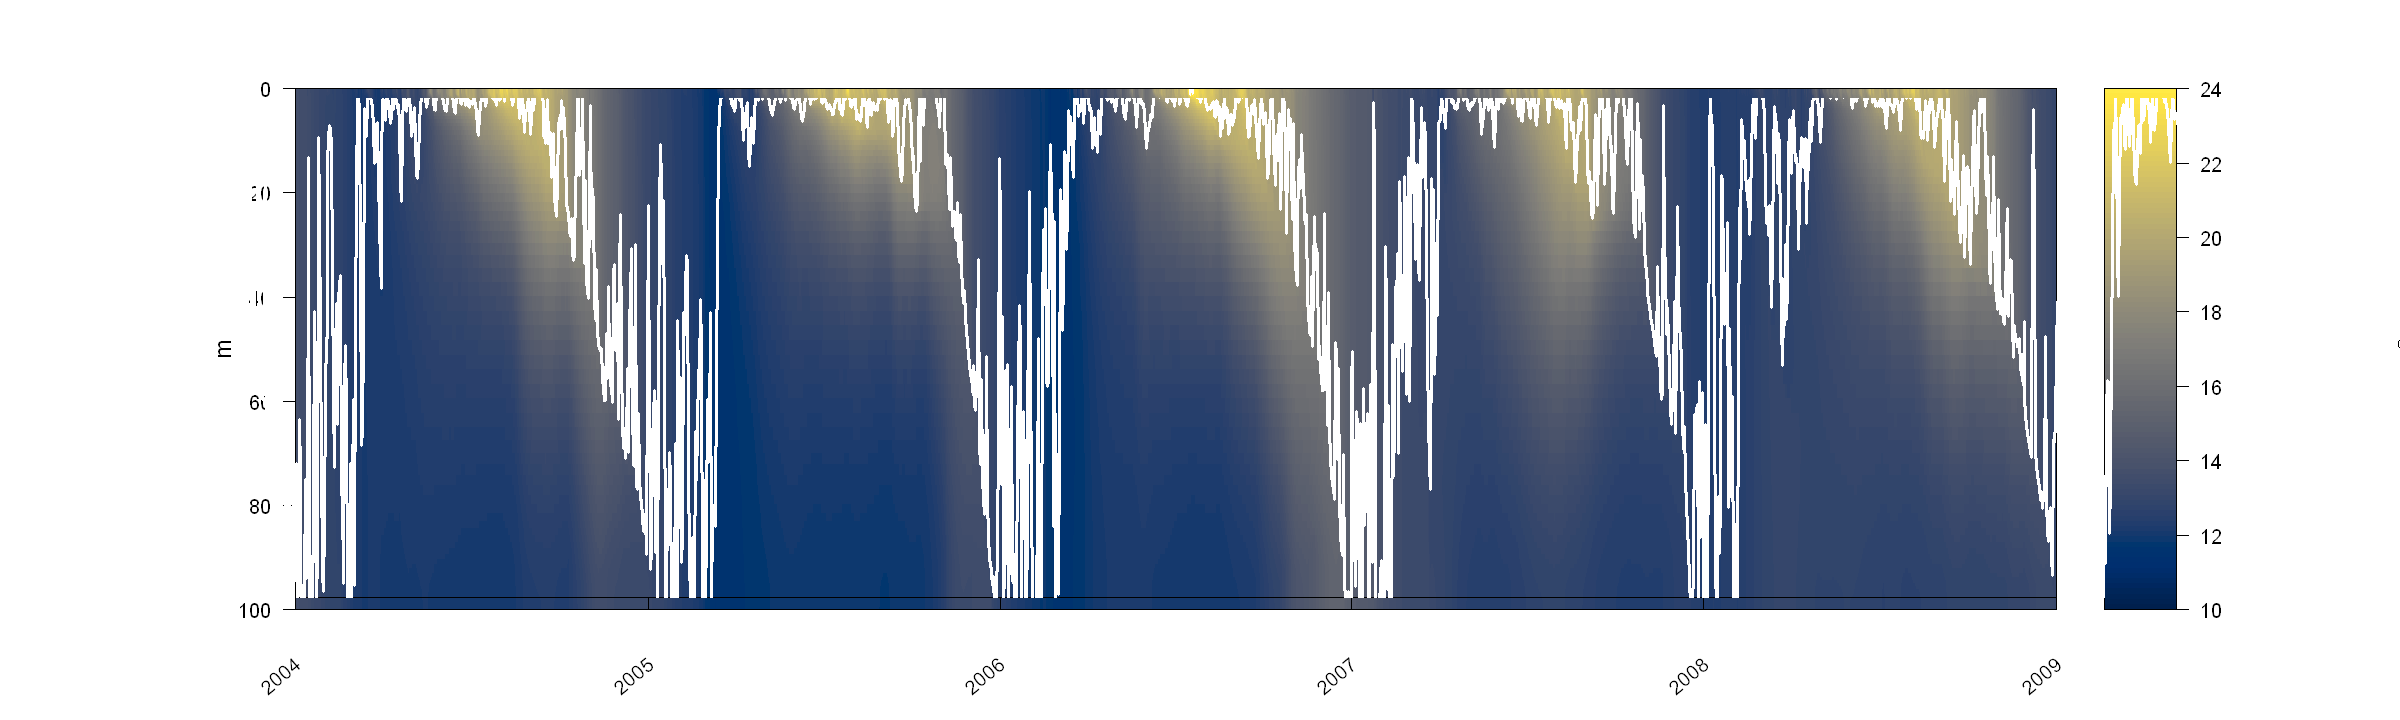

In [13]:
options(repr.plot.width = 18, repr.plot.height = 6)
## temperature
temp<-filerc$temp
#dim(temp)
image2D(y=depth_center, x=fechas, z=t(temp), las=1, cex.lab=1.2, col=cividis(100),
        ylab="m", xlab="", xaxt="n", ylim=c(100,0), zlim=c(10,24),main="", mgp=c(2.5,1,0),
        xlim=as.Date(c("2004-01-01","2009-01-01"),format="%Y-%m-%d"))
mtext(4, at=50, line=2, text=expression(paste(""^o,C,sep="")), outer=F, cex=1.0, las=1)
#contour(y=depth_center[length(depth_center):1], x=fechas, z=t(fliplr(temp)),levels=c(14,16,18,20), col="white", add=T)

axis(1, at=as.Date(c("2001-01-01","2002-01-01","2003-01-01","2004-01-01","2005-01-01","2006-01-01","2007-01-01","2008-01-01","2009-01-01")),
     labels=F, las=1, cex.axis=1.2, las=2,lwd.ticks=1.4)
text(x = as.Date(c("2001-01-01","2002-01-01","2003-01-01","2004-01-01","2005-01-01","2006-01-01","2007-01-01","2008-01-01","2009-01-01")),  y = par("usr")[3] + 10,
     labels = seq(2001,2009,by=1), xpd = NA,srt = 40,adj = 0.965,cex = 1.0)       

## MLD
mld<-filerc$mld_surf
points(x=fechas,mld,col="white", type="l", lwd=3)

El **Suministro de nutrientes a la capa de mezcla** permite explorar cómo la estructura física de la columna de agua condiciona el suministro de nutrientes hacia las capas superficiales donde se desarrolla gran parte de la actividad fitoplanctónica. El Resource Supply Index (RSI) combina la concentración de nitrato en la base de la zona eufótica, la estratificación de la columna de agua y la relación entre la profundidad de la capa de mezcla y la profundidad de la zona eufótica. **Posibles aplicaciones**: su inclusión en el análisis exploratorio puede ayudar a investigar las relaciones entre la estructura física, la disponibilidad de nutrientes y la dinámica del fitoplancton.

*Datos*: en este ejemplo, requiere perfiles de nutrientes y variables hidrográficas, así como información sobre la profundidad de la zona eufótica.

*Referencias*:
Marañón, E.; Cermeño, P.; Huete-Ortega, M.; López-Sandoval, D.C.; Mouriño-Carballido, B.; Rodríguez-Ramos, T. (2014) Resource Supply Overrides Temperature as a Controlling Factor of Marine Phytoplankton Growth. PLoSONE9(6):e99312. https://doi.org/10.1371/journal.pone.0099312

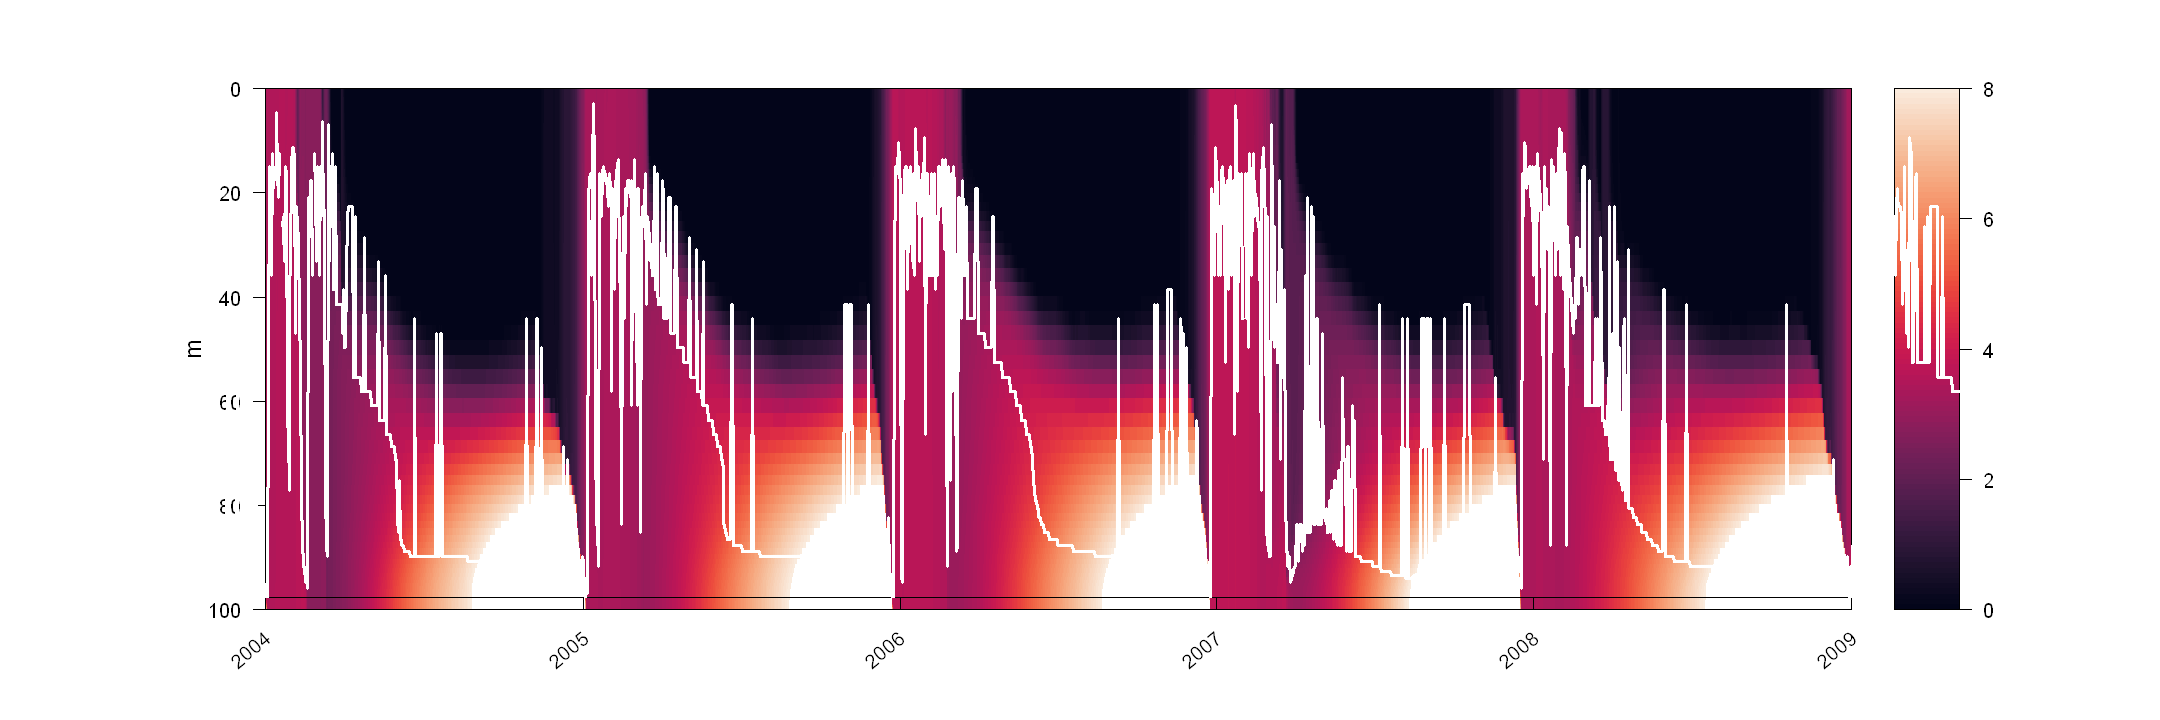

In [16]:
options(repr.plot.width = 18, repr.plot.height = 6)

### nitrate    
nitrate<-filerc$N3_n
image2D(y=depth_center, x=fechas, z=t(nitrate), las=1, cex.lab=1.2, col=rocket(100), #col=rainbow(100)[75:1],
        ylab="m", xlab="", xaxt="n", ylim=c(100,0), zlim=c(0,8.0),main="", mgp=c(2.5,1,0),
        xlim=as.Date(c("2004-01-01","2009-01-01"),format="%Y-%m-%d"))
mtext(4, at=90, line=2, text=expression(paste("mmol N ",m^-3,sep="")), outer=F, cex=0.8)
#mtext(4, at=50, line=2, text=expression(paste("mgChl  ",m^-3,sep="")), outer=F, cex=1.0)
axis(1, at=as.Date(c("2001-01-01","2002-01-01","2003-01-01","2004-01-01","2005-01-01","2006-01-01","2007-01-01","2008-01-01","2009-01-01")),
     labels=F, las=1, cex.axis=1.2, las=2,lwd.ticks=1.4)
text(x = as.Date(c("2001-01-01","2002-01-01","2003-01-01","2004-01-01","2005-01-01","2006-01-01","2007-01-01","2008-01-01","2009-01-01")),  y = par("usr")[3] + 5,
     labels = seq(2001,2009,by=1), xpd = NA,srt = 40,adj = 0.965,cex = 1.0)       


# Nutricline
myfun_iso<-function(x, n){
  res<-which(abs(x-n)==min(abs(x-n),na.rm=T))
  if (length(res)>1) res<-res[1]
  return(res)}

# Nutricline with threshold criterium
myfun_iso<-function(x, n){
  #dim(TChlao)
  #x=TChlao[,1]
  #length(x)
  #n=0.02
  #diff(x)
  #plot(c(2:196),diff(x))  
  res<-which(abs(diff(x)+n)==min(abs(diff(x)+n),na.rm=T))       
  if (length(res)>1) res<-NA #res[1]
  return(res)} 

# Find isoline
isopic<-apply(nitrate, MARGIN=2, FUN=myfun_iso, n=0.08)    # these are indexes not depths
pic_depth<-depth_center[isopic]
points(x=fechas,pic_depth,col="white", type="l", lwd=3)

El **Deep Chlorophyll Maximum (DCM)** es la profundidad a la que se observa el máximo de clorofila dentro de un perfil vertical, cuando existe. Es un indicador útil para explorar la estructura vertical de la comunidad fitoplanctónica. Conviene distinguir la profundidad del máximo de clorofila de la profundidad del máximo de biomasa: no siempre coinciden. **Posibles aplicaciones**: estudiar la evolución estacional de la estructura vertical, explorar su relación con la MLD y evaluar si su profundidad puede predecirse a partir de variables ambientales.

*Datos*: en este ejemplo, perfiles de clorofila indexados con profundidad. Desde datos in situ suelen usarse perfiles de clorofila derivada de fluorescencia.

*Referencias*:
Latasa, M.: Cabello, A.M.; Morán, X.A.G.; Massana, R.; Scharek, R. (2017) Distribution of phytoplankton groups within the deep chlorophyll
Máximum. Limnol. Oceanogr. 62:665–685. https://doi.org/10.1002/lno.10452

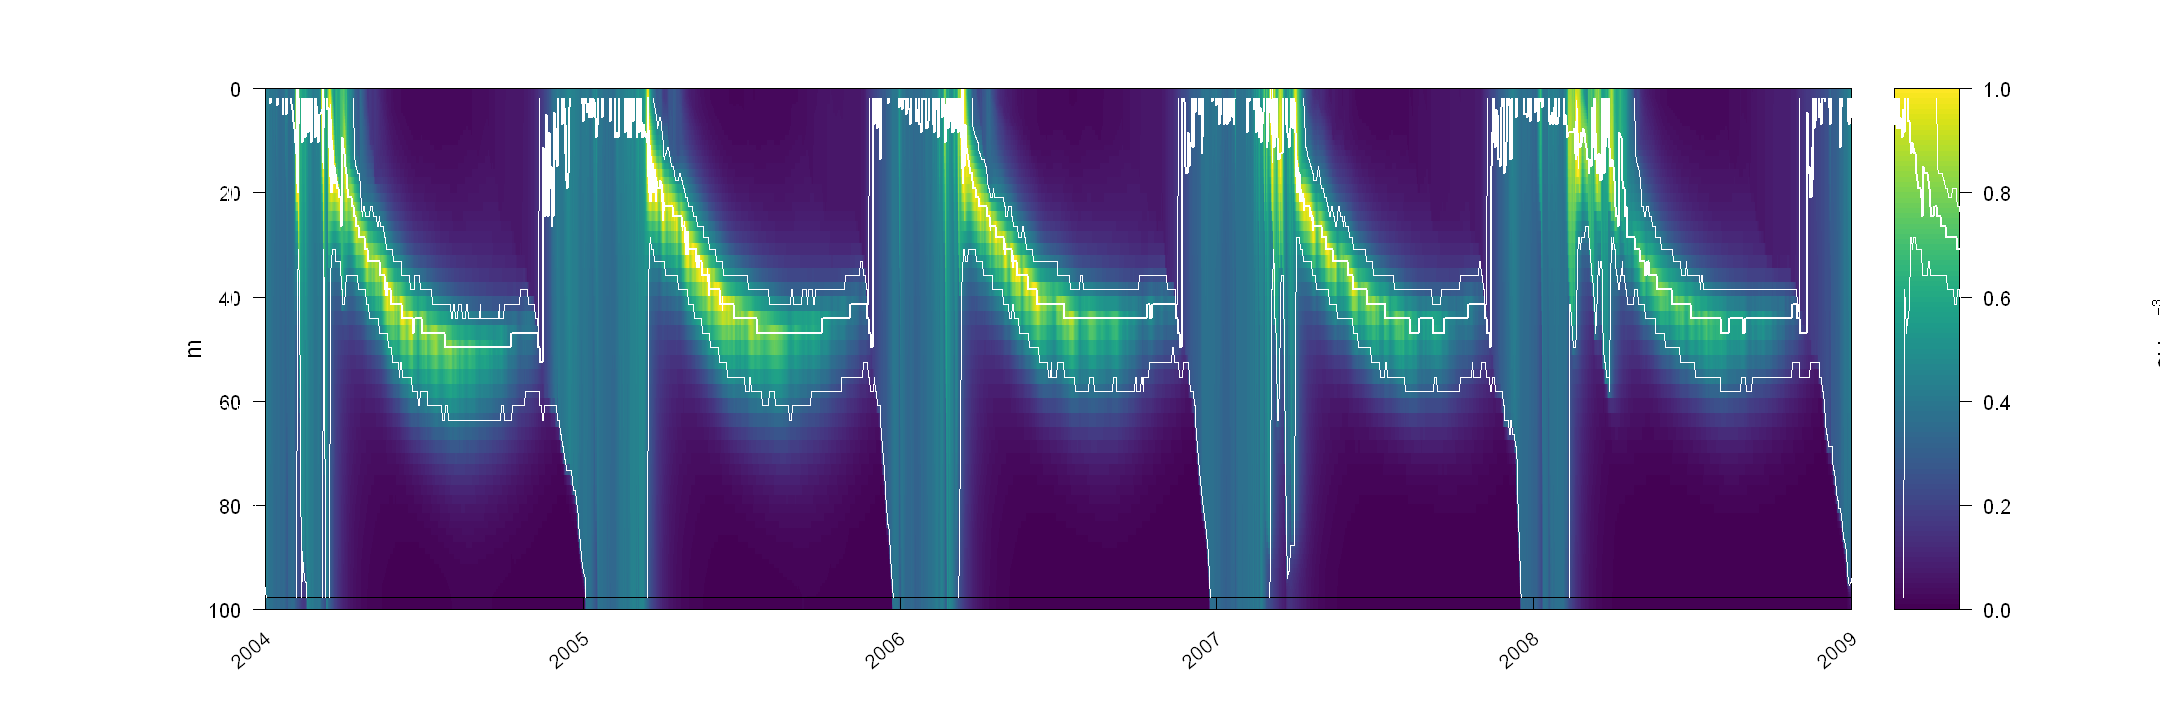

In [17]:
## Chl-a   
TChla<-filerc$total_chlorophyll
image2D(y=depth_center, x=fechas, z=t(TChla), las=1, cex.lab=1.2, col=viridis(100), #col=rainbow(100)[75:1],
        ylab="m", xlab="", xaxt="n", ylim=c(100,0), zlim=c(0,1.0),main="", mgp=c(2.5,1,0),
        xlim=as.Date(c("2004-01-01","2009-01-01"),format="%Y-%m-%d"))
mtext(4, at=50, line=2, text=expression(paste("mgChl  ",m^-3,sep="")), outer=F, cex=1.0)
axis(1, at=as.Date(c("2001-01-01","2002-01-01","2003-01-01","2004-01-01","2005-01-01","2006-01-01","2007-01-01","2008-01-01","2009-01-01")),
     labels=F, las=1, cex.axis=1.2, las=2,lwd.ticks=1.4)
text(x = as.Date(c("2001-01-01","2002-01-01","2003-01-01","2004-01-01","2005-01-01","2006-01-01","2007-01-01","2008-01-01","2009-01-01")),  y = par("usr")[3] + 5,
     labels = seq(2001,2009,by=1), xpd = NA,srt = 40,adj = 0.965,cex = 1.0)       

# Find DCM
myfun<-function(x){ res<-which(x==max(x,na.rm=T))
if (length(res)>1) res<-res[1]
return(res)}

dcm<-apply(TChla, MARGIN=2, FUN=myfun)      # these are indexes not depths
dcm_depth<-depth_center[dcm]
points(x=fechas,dcm_depth, col="white", type="l", lwd=2)


# Width DCM
x<-TChla[,100]
mlfun<-function(x){
  umbral<-(max(x,na.rm=T)-min(x,na.rm=T))/2
  pixels<-which(x>=umbral)
  res<-range(pixels,na.rm=T)
  return(res)}

dcm_width<-apply(TChla, MARGIN=2, FUN=mlfun) # these are indexes not depths
dcm_lower<-depth_center[dcm_width[1,]]
dcm_upper<-depth_center[dcm_width[2,]]

points(x=fechas,dcm_lower, col="white", type="l", lwd=1)
points(x=fechas,dcm_upper, col="white", type="l", lwd=1)

### 2.2. Calculo de indicadores en series

Los **indicadores fenológicos** permiten describir el calendario de eventos biológicos, como el inicio, el máximo y el final de una floración fitoplanctónica, así como su duración o intensidad. Su cálculo exige definir previamente qué se considera una floración y cómo se detectan sus límites. Los resultados pueden ser poco robustos si existen grandes huecos de muestreo. **Posibles aplicaciones**: comparar la temporalidad de las floraciones entre años, explorar su relación con variables ambientales y estudiar cambios en el calendario estacional.

*Datos*: serie temporale de clorofila a un profundidad fija y/o en el DCM.

*Referencias*:
Llort, J.: Lévy, M.: Sallée, J.B.; Tagliabue, A. (2015) Onset, intensification, and decline of phytoplankton blooms in the Southern Ocean. ICES Journal of Marine Science 72 (6): 1971–1984. https://doi.org/10.1093/icesjms/fsv053

In [ ]:
## pendiente

## 3. Formatear el dataset para análisis posteriores

In [19]:
filename <- "../seamless-notebooks/setups/E2GI/result.nc"
filenc <- open.nc(filename)
filerc <- read.nc(filenc)
#names(filerc)
tiempo<-filerc$time/86400
fechas<-as.Date(tiempo,origin="2002-01-01")

## Seleccionar solo superficie
model_m <- data.frame(fecha=fechas,
                      temp = filerc$temp[93,],
                      sal = filerc$salt[93,],
                      chla = filerc$total_chlorophyll[93,],
                      nitrate = filerc$N3_n[93,],
                      phosphate = filerc$N1_p[93,],
                      o2 = filerc$O2_o[93,])

# Mostrar el resultado
head(model_m, 2)

,fecha,temp,sal,chla,nitrate,phosphate,o2
,<date[1d]>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2002-01-01,12.48433,35.48239,0.6390000,4.533329,0.2772227,264.6111
2,2002-01-02,12.66457,35.55835,0.6354859,4.610121,0.2755726,262.5401


In [21]:
# Guardar df como CSV
write.csv(model_m,"../data/processed/Model_E2GI_surface_daily.csv",
  row.names = FALSE,
  na = "")
##########
colnames(model_m)

[1] "fecha"     "temp"      "sal"       "chla"      "nitrate"   "phosphate"
[7] "o2"

Identificar qué indicadores podrían ser objetivos de predicción y cuáles podrían utilizarse como variables explicativas.